<h1> TP transfer - Deep Learning </h1>

<hr/>

<b>N'envoyez pas votre travail par mail :</b>
- Zippez votre fichier notebook, et nommez l'archive avec votre nom
- Envoyez l'archive via Ametice
<hr/>

Un musée spécialisé en peintures représentant des animaux de la savane a malheureusement perdu son fichier d'inventaire qui regroupait des informations précieuses sur les 2000 oeuvres du musée ! Fort heureusement, l'informaticien toujours prévoyant avait conservé une copie des 2000 photos des oeuvres, et il vient juste de suivre une formation de Deep Learning ...

<center>
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/0.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/1.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/2.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/3.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/4.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/5.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/6.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/7.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/8.jpg" width="90px" />
<img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/9.jpg" width="90px" />
</center>

Cet examen porte sur la résolution d'une tâche de classification d'images sur un jeu de données faiblement annoté. Plusieurs solutions sont envisagées  consistant à tirer parti d'annotations de classes équivalentes sur un autre dataset entièrement étiquetté (imagenet). Les deux jeux de données contiennent 2000 images réparties (également) en quatre classes (d'animaux : zèbres, gorilles, léopards, tigres). 1500 images sont utilisées pour l'entrainement, 500 pour l'évaluation. Seul le jeu de données A (imagenet) est complètement annoté, le dataset B (les photos des oeuvres du musée) ne contient que très peu d'annotations.

La partie 1 consiste à entrainer et évaluer les performances d'un modèle CNN fourni sur les deux datasets d'images. Les parties 2 et 3 consistent à mettre en oeuvre deux solutions par <i>adaptation de domaines</i> pour tenter d'améliorer les performances de classification sur le dataset faiblement annoté. Vous pouvez consacrer environ une heure à chaque partie, notées également.


<h3> Téléchargement des données </h3>

In [ ]:
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/imagenetXtrain.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/imagenetYtrain.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/imagenetXtest.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/imagenetYtest.npy

!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/awaXtrain.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/awaYtrain.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/awaXtest.npy
!wget https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/awaYtest.npy

<h3>Chargement des données</h3>

In [1]:
import numpy as np
from random import shuffle
import tensorflow as tf
keras = tf.keras
import matplotlib.pyplot as plt
import keras.backend as K
from keras.layers import Input, Dense, Flatten, LeakyReLU
from keras.layers import AveragePooling2D, Conv2D, Activation, BatchNormalization, Dropout
from keras.models import Model
from keras.optimizers import Adam

In [ ]:
path = './datasets/'
num_classes = 4

x_trainA = np.load(path+'imagenetXtrain.npy')
x_trainA = x_trainA / 255.
y_trainA = np.load(path+'imagenetYtrain.npy')
y_trainA = keras.utils.to_categorical(y_trainA, num_classes)

x_testA = np.load(path+'imagenetXtest.npy')
x_testA = x_testA / 255.
y_testA = np.load(path+'imagenetYtest.npy')
y_testA = keras.utils.to_categorical(y_testA, num_classes)

x_trainB = np.load(path+'awaXtrain.npy')
x_trainB = x_trainB / 255.
y_trainB = np.load(path+'awaYtrain.npy')
y_trainB = keras.utils.to_categorical(y_trainB, num_classes)

x_testB = np.load(path+'awaXtest.npy')
x_testB = x_testB / 255.
y_testB = np.load(path+'awaYtest.npy')
y_testB = keras.utils.to_categorical(y_testB, num_classes)

print('x_trainA.shape:', x_trainA.shape, 'y_trainA.shape:', y_trainA.shape)
print('x_trainB.shape:', x_trainB.shape, 'y_trainB.shape:', y_trainB.shape)

print('x_testA.shape:', x_testA.shape, 'y_testA.shape:', y_testA.shape)
print('x_testB.shape:', x_testB.shape, 'y_testB.shape:', y_testB.shape)



x_trainA.shape: (1500, 64, 64, 3) y_trainA.shape: (1500, 4)
x_trainB.shape: (1500, 64, 64, 3) y_trainB.shape: (50, 4)
x_testA.shape: (500, 64, 64, 3) y_testA.shape: (500, 4)
x_testB.shape: (500, 64, 64, 3) y_testB.shape: (500, 4)


Les deux jeux de données contiennent 2000 images, de 64x64x3 pixels, réparties en quatre classes. 1500 images sont utilisées pour l'entrainement, 500 pour l'évaluation. Seul le jeu de données A est complètement annoté, le jeu de donnée B ne contient que très peu d'annotations, correspondantent aux 50 premiers exemples de x_trainB.

<h2> Partie 1 : Modèle convolutionnel pour la classification d'images </h2>

On définie ci-dessous une architecture convolutionnelle simple, à ne pas modifier. Cette partie vise à évaluer la performance d'un modèle CNN sur les deux dataset A et B. Entrainez ce modèle des différentes manières possibles et reportez les performances obtenues dans le tableau situé en fin de cette partie. A chaque nouvel apprentissage, utilisez les configurations suivantes :
- 30 epochs
- Taille des minibatchs à 64
- 10% des données pour validation

Tracez les courbes d'apprentissage, et commentez vos résultats.

In [7]:
# Couches d'apprentissage de représentations par convolutions
def create_model():
  ximg = Input(shape=(x_trainA.shape[1], x_trainA.shape[2], x_trainA.shape[3]))

  l = Conv2D(64, kernel_size=(3,3), strides=(1,1), padding='same')(ximg)
  l = BatchNormalization(axis=-1)(l)
  l = Activation('relu')(l)
  l = Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same')(l)
  l = BatchNormalization(axis=-1)(l)
  l = Activation('relu')(l)
  l = Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same')(l)
  l = BatchNormalization(axis=-1)(l)
  l = Activation('relu')(l)
  l = AveragePooling2D((4,4))(l)
  l = Conv2D(256, kernel_size=(3,3), strides=(2,2), padding='same')(l)
  l = BatchNormalization(axis=-1)(l)
  l = Conv2D(256, kernel_size=(3,3), strides=(1,1), padding='same')(l)
  l = AveragePooling2D((2,2))(l)
  l = Activation('relu')(l)
  l = Dropout(0.2)(l)
  feat_layer = Flatten()(l)

  # conv_model(ximg) retourne la couche 'feat_layer' : 4096 dimensions pour une image 64x64x3
  conv_model = Model(ximg, feat_layer)

  # Couches de classification
  xfeat = Input(shape=(4096,))
  y = Dense(1024, activation='relu')(xfeat)
  y = Dropout(0.5)(y)
  y = Dense(512, activation='relu')(y)
  out_layer = Dense(num_classes, activation='softmax')(y)

  # classif_model(xfeat) renvoie la couche sortie du classifieur : 4 dimensions
  classif_model = Model(xfeat, out_layer)

  # Modèle CNN : représentation + classifier
  feat = conv_model(ximg)
  clf = classif_model(feat)
  model = Model(ximg, clf)
  model.compile(loss='categorical_crossentropy', optimizer=Adam(0.0001), metrics=['accuracy'])
  print(model.summary())

  return (model, conv_model, classif_model)

<h4> Entrainement du modèle sur les données A, puis évaluation sur A et B</h4>

In [ ]:
# A compléter
model_A, conv_model_A, classif_model_A = create_model()
history_A = model_A.fit(x_trainA, y_trainA, batch_size=64, epochs=30, validation_split=0.1)
print("Evaluation A:", model_A.evaluate(x_testA, y_testA))
print("Evaluation B:", model_A.evaluate(x_testB, y_testB))

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 4096)           │     1,110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 4)              │     4,722,180 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,832,964 (22.25 MB)

 Trainable params: 5,831,812 (22.25 MB)

 Non-trainable params: 1,152 (4.50 KB)

None
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 48s 932ms/step - accuracy: 0.4422 - loss: 1.2281 - val_accuracy: 0.2600 - val_loss: 1.3857
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.5963 - loss: 0.9500 - val_accuracy: 0.2333 - val_loss: 1.3797
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.6341 - loss: 0.8333 - val_accuracy: 0.2467 - val_loss: 1.3893
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.6911 - loss: 0.7339 - val_accuracy: 0.2200 - val_loss: 1.4124
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.7281 - loss: 0.6882 - val_accuracy: 0.2067 - val_loss: 1.4780
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.7356 - loss: 0.6556 - val_accuracy: 0.2200 - val_loss: 1.4154
Epoch 7/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.7763 - loss: 0.5661 - val_accuracy: 0.3533 - val_loss: 1.3691
Epoch 8/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8096 - loss: 0.5018 - val_accuracy: 0.3

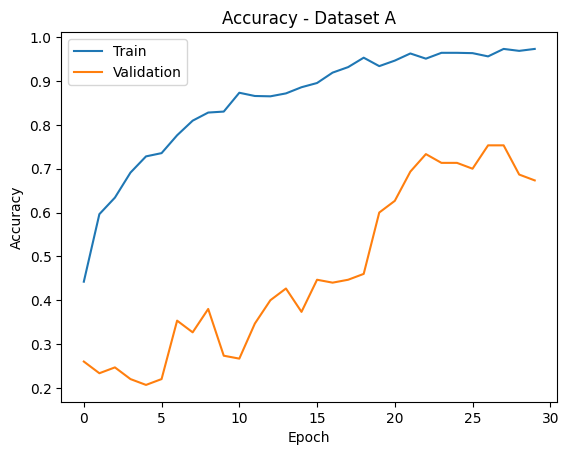

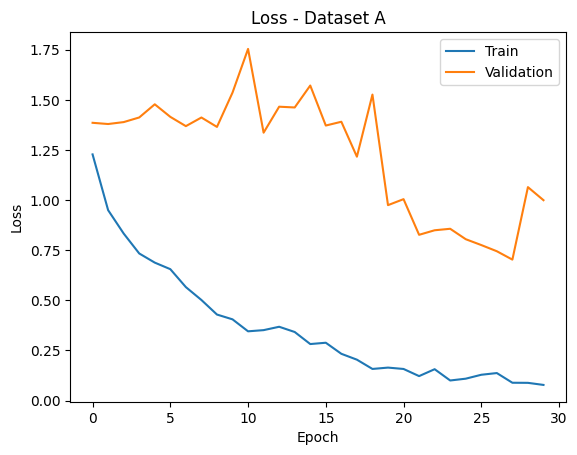

In [ ]:
# Accuracy
plt.plot(history_A.history['accuracy'], label='Train')
plt.plot(history_A.history['val_accuracy'], label='Validation')
plt.title('Accuracy - Dataset A')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(history_A.history['loss'], label='Train')
plt.plot(history_A.history['val_loss'], label='Validation')
plt.title('Loss - Dataset A')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Commentaires :
On observe que, à chaque époque, la précision et la perte, tant pour l'entraînement que pour la validation, ont tendance à augmenter et à diminuer, respectivement. Toutefois, les résultats obtenus lors de la validation ne sont à aucun moment aussi bons que ceux obtenus lors de l'entraînement. Cela se répercute sur la phase de test, qui affiche une perte élevée et une faible précision, notamment lors de l'évaluation sur les données de l'ensemble B. On peut donc affirmer que le modèle ne généralise pas suffisamment bien les données d'entraînement pour constituer une approche optimale permettant d'évaluer les deux ensembles de données, en particulier l'ensemble B.

<h4> Entrainement et évaluation du modèle sur les données B</h4>

<i>Attention à ne pas réutiliser la variable <b>model</b>, déjà entrainée sur A, il faut créer une nouvelle instance <b>model2</b> à partir des fonctions <b>conv_model()</b> et <b>classif_model()</b> définient précédemment.</i>

In [ ]:
# A compléter
model_B, conv_model_B, classif_model_B = create_model()
history_B = model_B.fit(x_trainB[:50], y_trainB[:50], batch_size=64, epochs=30, validation_split=0.1)
print(model_B.evaluate(x_testA, y_testA))
print(model_B.evaluate(x_testB, y_testB))


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_3 (Functional)       │ (None, 4096)           │     1,110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_4 (Functional)       │ (None, 4)              │     4,722,180 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,832,964 (22.25 MB)

 Trainable params: 5,831,812 (22.25 MB)

 Non-trainable params: 1,152 (4.50 KB)

None
Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 24s 24s/step - accuracy: 0.2667 - loss: 1.5227 - val_accuracy: 0.6000 - val_loss: 1.3824
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.5333 - loss: 1.1302 - val_accuracy: 0.4000 - val_loss: 1.3822
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.6222 - loss: 0.9184 - val_accuracy: 0.4000 - val_loss: 1.3822
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6444 - loss: 0.8550 - val_accuracy: 0.4000 - val_loss: 1.3812
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.7333 - loss: 0.7246 - val_accuracy: 0.2000 - val_loss: 1.3791
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.8444 - loss: 0.5833 - val_accuracy: 0.2000 - val_loss: 1.3780
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8000 - loss: 0.5179 - val_accuracy: 0.2000 - val_loss: 1.3777
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8444 - loss: 0.4642 - val_accuracy: 0.2000 - val_l

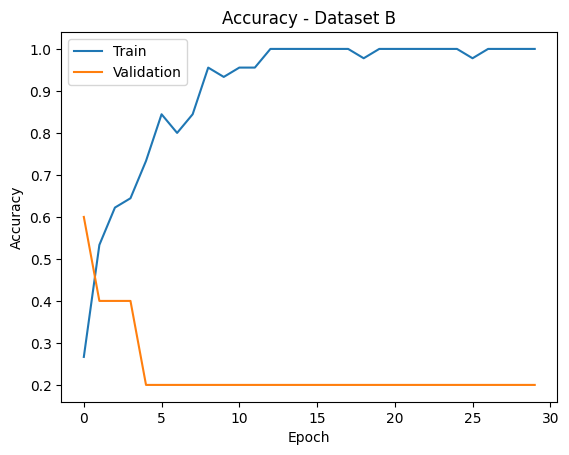

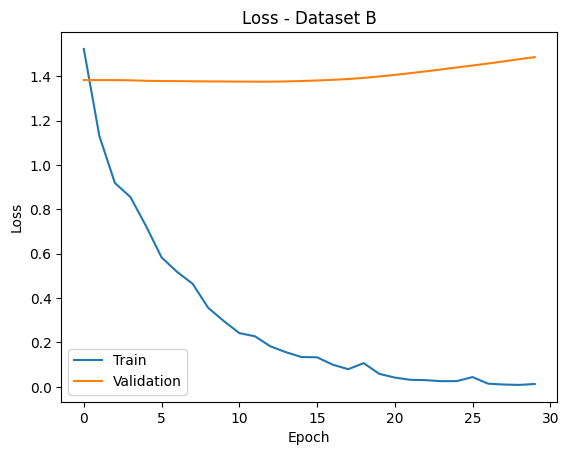

In [ ]:
# Accuracy
plt.plot(history_B.history['accuracy'], label='Train')
plt.plot(history_B.history['val_accuracy'], label='Validation')
plt.title('Accuracy - Dataset B')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(history_B.history['loss'], label='Train')
plt.plot(history_B.history['val_loss'], label='Validation')
plt.title('Loss - Dataset B')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Commentaires : Comme nous n'utilisons que 50 instances étiquetées issues du jeu de données B, le modèle n'apprend rien en matière de généralisation, car il ne dispose pas de suffisamment de données pour effectuer un entraînement pertinent.

<h4>Finetuning sur B du modèle entrainé sur A</h4>

In [ ]:
# A compléter
model_AB, conv_model_AB, classif_model_AB = create_model()
model_AB.set_weights(model_A.get_weights())

history_AB = model_AB.fit(x_trainB[:50], y_trainB[:50], batch_size = 64, epochs = 30, validation_split = 0.1)
print(model_AB.evaluate(x_testA, y_testA))
print(model_AB.evaluate(x_testB, y_testB))

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_9 (Functional)       │ (None, 4096)           │     1,110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_10 (Functional)      │ (None, 4)              │     4,722,180 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,832,964 (22.25 MB)

 Trainable params: 5,831,812 (22.25 MB)

 Non-trainable params: 1,152 (4.50 KB)

None
Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.6444 - loss: 1.5222 - val_accuracy: 0.8000 - val_loss: 1.0008
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.7111 - loss: 0.6451 - val_accuracy: 0.8000 - val_loss: 0.8552
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.8667 - loss: 0.2764 - val_accuracy: 0.8000 - val_loss: 0.8717
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.9333 - loss: 0.2184 - val_accuracy: 0.8000 - val_loss: 0.9787
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.9111 - loss: 0.1726 - val_accuracy: 0.8000 - val_loss: 1.1236
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 1.0000 - loss: 0.0477 - val_accuracy: 0.8000 - val_loss: 1.2767
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 1.0000 - loss: 0.0521 - val_accuracy: 0.8000 - val_loss: 1.4211
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 1.0000 - loss: 0.0606 - val_accuracy: 0.8000 - val_los

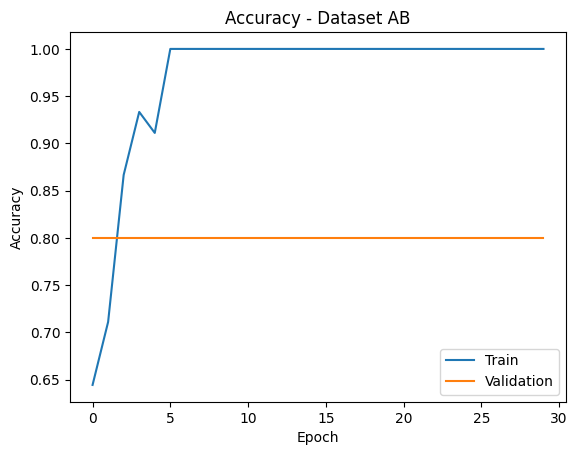

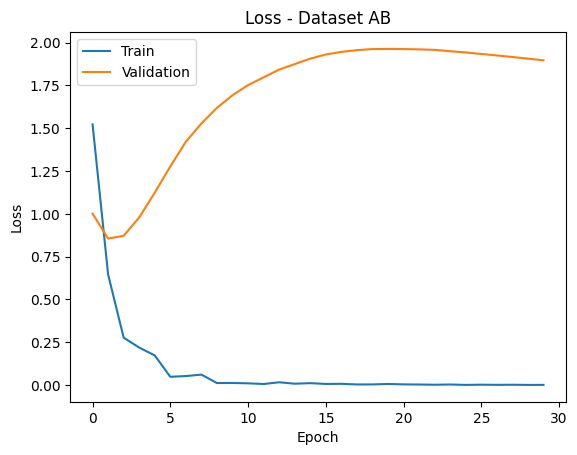

In [ ]:
# Accuracy
plt.plot(history_AB.history['accuracy'], label='Train')
plt.plot(history_AB.history['val_accuracy'], label='Validation')
plt.title('Accuracy - Dataset AB')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(history_AB.history['loss'], label='Train')
plt.plot(history_AB.history['val_loss'], label='Validation')
plt.title('Loss - Dataset AB')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Commentaires :

<table>
  <thead>
    <th></th><th>Accuracy train A</th><th>Accuracy dev A</th><th>Accuracy test A</th><th>Accuracy train B</th><th>Accuracy dev B</th><th>Accuracy test B</th>
  </thead>
  <tbody>
    <tr><th>Entrainement sur A</th><td>0.9733</td><td>0.6733</td><td>0.6959</td><td></td><td></td><td>0.5460</td></tr>
    <tr><th>Entrainement sur B</th><td></td><td></td><td>0.2660</td><td>1.0000</td><td>0.2000</td><td>0.2419</td></tr>
    <tr><th>Entrainement sur A <br/>+ Finetuning sur B</th><td></td><td></td><td>0.5220</td><td>1.0000</td><td>0.8000</td><td>0.4979</td></tr>
  </tbody>
</table>

Commentaires : Le fine-tuning a permis d'obtenir une accuracy beaucoup plus satisfaisante sur le jeu de données B par rapport au modèle précédent. Cependant, le modèle actuel est encore loin d'être idéal, car la loss de validation est très élevée et l'accuracy sur le jeu de test reste faible, ce qui indique un possible surapprentissage. Ainsi, aucun scénario n'est idéal. Toutefois, compte tenu des approches disponibles, l'entraînement sur A est la meilleure option pour le jeu de données A, tandis que l'entraînement sur A suivi d'un finetuning sur B est la meilleure option pour le jeu de données B.




<h2>Partie 2 : Adaptation de domaine par alignement des activations</h2>

Cette partie consiste à implémenter et évaluer un modèle inspiré de l'article <a href="https://arxiv.org/pdf/1607.01719.pdf">Deep CORAL: Correlation Alignment for Deep Domain Adaptation [Sun & Saenko, 2016] </a>, dont la figure suivante illustre le fonctionnement.

<center><img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/coral16.png" width="50%" /></center>

Considérez les instructions suivantes :
- Utilisez les mêmes modules de convolutions que dans la Partie 1 afin de rester comparable. Pour cela, considérez une nouvelle instance <b>conv_model3</b> comme effectué précédemment.
- Seules les couches de convolutions sont partagées. cf https://keras.io/getting-started/functional-api-guide/#shared-layers
- Seulement deux couches denses après les convolutions (ie: fc6 et fc7), dropout entre les deux.
- Version simplifiée de la <i>CORAL loss</i> : minimisation de la distance entre les dernières couches denses (et/ou maximisation de la corrélation). Utilisez l'une des couches documentées sur la page suivante : https://keras.io/layers/merge/
- Entrainez pendant 50 epochs, avec minibatchs = 128


<h4> Définition du modèle </h4>

xA et xB sont les données des deux domaines, yA est la sortie du classifieur pour les données de xA dans le domaine source, et <i>coral</i> correspond à la métrique (distance ou corrélation) entre un minibatch d'exemples xA et xB, dans les deux domaines. Le modèle optimise les deux loss : <i>categorical_crossentropy</i> pour classer les images du domaine source ; et <i>mse</i> qui minimise (ou maximise) la métrique considérée.


In [8]:
xA = Input(shape=(x_trainA.shape[1], x_trainA.shape[2], x_trainA.shape[3]))
xB = Input(shape=(x_trainA.shape[1], x_trainA.shape[2], x_trainA.shape[3]))

# création du modèle CORAL
(_, conv_model, classif_modelA) = create_model()
featA = conv_model(xA)
featB = conv_model(xB)

(_, _, classif_modelB) = create_model()
yA = classif_modelA(featA)
yB = classif_modelB(featB)

coral = keras.layers.Dot(axes=1, normalize=True)([yA, yB])

model4 = Model([xA,xB],[yA, coral])
model4.compile(loss=['categorical_crossentropy','mse'], optimizer=Adam(0.0001), metrics=[['accuracy'], []])
print(model4.summary())

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 4096)           │     1,110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 4)              │     4,722,180 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,832,964 (22.25 MB)

 Trainable params: 5,831,812 (22.25 MB)

 Non-trainable params: 1,152 (4.50 KB)

None


... (8 outputs left out)

 Total params: 10,555,144 (40.26 MB)

 Trainable params: 10,553,992 (40.26 MB)

 Non-trainable params: 1,152 (4.50 KB)

None


<h4> Entrainement du modèle d'adaptation par alignement </h4>

Selon le critère <i>coral</i> que vous optimisez, considérez le vecteur objectif ne contenant que des 1 ou que des 0..

In [9]:
ones = np.ones((len(x_trainA),1)) # ou zeros = np.zeros((len(x_trainA),1))

# A compléter
res4 = model4.fit([x_trainA, x_trainB], [y_trainA, ones], batch_size=128, epochs=50, validation_split=0.1)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 71s 3s/step - dot_loss: 0.0830 - functional_1_accuracy: 0.3496 - functional_1_loss: 1.3717 - loss: 1.4623 - val_dot_loss: 2.8481e-08 - val_functional_1_accuracy: 0.3000 - val_functional_1_loss: 1.3836 - val_loss: 1.3840
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 304ms/step - dot_loss: 0.0701 - functional_1_accuracy: 0.5385 - functional_1_loss: 1.0655 - loss: 1.1420 - val_dot_loss: 9.4359e-08 - val_functional_1_accuracy: 0.2333 - val_functional_1_loss: 1.3867 - val_loss: 1.3867
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 327ms/step - dot_loss: 0.0791 - functional_1_accuracy: 0.6170 - functional_1_loss: 0.9160 - loss: 0.9991 - val_dot_loss: 4.8396e-05 - val_functional_1_accuracy: 0.2067 - val_functional_1_loss: 1.3970 - val_loss: 1.3924
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 306ms/step - dot_loss: 0.0938 - functional_1_accuracy: 0.6541 - functional_1_loss: 0.8359 - loss: 0.9291 - val_dot_loss: 1.8542e-04 - val_functional_1_accuracy: 0.2067 - val_functi

Commentaires : L'entraînement a atteint une excellente précision de 99,70%. Cependant, la validation présente des métriques instables accompagnées de loss élevées. La précision de 78,67% indique que cette approche est pertinente pour l'entraînement sur le jeu de données B, mais révèle également un problème de overfitting.

<h4>Evaluation sur les datasets A et B</h4>

In [10]:
# A compléter
eval_A = Model(xA, yA)
eval_B = Model(xB, yB)

eval_A.compile(loss='categorical_crossentropy', metrics=['accuracy'])
eval_B.compile(loss='categorical_crossentropy', metrics=['accuracy'])

print(eval_A.evaluate(x_testA, y_testA))
print(eval_B.evaluate(x_testB, y_testB))

16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 253ms/step - accuracy: 0.7360 - loss: 1.2383
[1.2383428812026978, 0.7360000014305115]
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.2380 - loss: 1.6284
[1.6283924579620361, 0.23800000548362732]


Commentaires :

L'accuracy du dataset A obtenue lors du test de la partie 1 (67,33%) est inférieure à celle obtenue dans l'expérience actuelle (73,60%). Cependant, l'accuracy du dataset B obtenue dans la partie 1 (49,79%) est supérieure à celle de l'expérience actuelle (23,80%). Ainsi, on peut conclure que cette nouvelle approche n'est pas idéale pour les datasets disposant de peu de données annotées. Le modèle entraîné sur A puis fine-tuning sur B a donc obtenu les meilleures performances sur le dataset B jusqu'à présent.

<h2>Partie 3 : Adaptation de domaine par contrainte adversarial</h2>

Cette partie consiste à implémenter un modèle d'adaptation de modèle par contrainte adversarial, inspiré de l'article <a href="http://openaccess.thecvf.com/content_cvpr_2017/papers/Tzeng_Adversarial_Discriminative_Domain_CVPR_2017_paper.pdf">Adversarial Discriminative Domain Adaptation [Tzeng, 2017]</a>.

<center><img src="https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/adversadapt17.png" width="80%" /></center>

Dans la figure ci-dessus, les modules en pointillés indiquent une réutilisation de modèles déjà entrainés, tandis que les modules en lignes pleines désignent des modèles nouvellement entrainés. Pour la phase de </i>Pre-training</i>, considérez le modèle entrainé sur le dataset A dans la partie 1.

La stratégie consiste donc à :
- Faire le prétraining du modèle source sur les données source avec un critère de classification. Cette étape a été faite en partie 1 : <b>conv_model</b> et <b>classif_model</b> sont déjà entrainés.
- Ne pas réentrainer ces deux modules.
- Apprendre from scratch le modèle extracteur de caractéristiques pour les données cible à l'aide d'un discriminateur adversarial appris à discriminer entre les données source transformées par le modèle préappris et les données du domaine cible transformées par le modèle cible.  
- Construire un classifieur en empilant la couche de classification du modèle source sur l'extracteur de caractéristiques sur les données cible.



<h4> Définition du modèle discriminateur </h4>
Le discriminateur à pour objectif de distinguer les domaines de deux sources de données (A et B) à parir de représentations extraites de couches de convolutions. Ecrivez un modèle simple à deux couches cachées.

In [35]:
# A compléter
def discriminator():
    inputs = Input(shape=(4096,))
    x = Dense(1024, activation='relu')(inputs)
    x = Dense(512, activation='relu')(x)
    outputs = Dense(1, activation='sigmoid')(x)

    d = Model(inputs, outputs)
    d.compile(optimizer=Adam(0.0001), loss='binary_crossentropy', metrics=['accuracy'])
    return d

<h4> Modèle adversarial </h4>

Ecrivez ci-dessous le modèle adversarial qui combine le module <i>Target CNN</i> et le discriminateur. <i>Target CNN</i> consistera en une nouvelle instance <b>conv_model4</b> pour extraire des représentations similaires au modèle entrainé en Partie 1 sur les images sources.

In [36]:
# A compléter
conv_model = conv_model_A
classif_model = classif_model_A
conv_model.trainable = False
classif_model.trainable = False

(_, conv_model4, _) = create_model()

d = discriminator()

input_B = Input(shape=(64, 64, 3))
features_B = conv_model4(input_B)

d.trainable = False
domain_B = d(features_B)

adv_model = Model(input_B, domain_B)
adv_model.compile(optimizer=Adam(0.0001), loss='binary_crossentropy')
d.trainable = True
d.compile(optimizer=Adam(0.0001), loss='binary_crossentropy', metrics=['accuracy'])

Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_30 (Functional)      │ (None, 4096)           │     1,110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_31 (Functional)      │ (None, 4)              │     4,722,180 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,832,964 (22.25 MB)

 Trainable params: 5,831,812 (22.25 MB)

 Non-trainable params: 1,152 (4.50 KB)

None


<h4> Modèle utilisé en phase de test </h4>

Construisez ci-dessous le modèle final qui combine les modules <i>Target CNN</i>  (<b>conv_model4</b>) entrainés précédemment et <b>classif_model</b> entrainé en Partie 1.

In [37]:
# A compléter
input_test = Input(shape = (64, 64, 3))
features_test = conv_model4(input_test)
predictions = classif_model(features_test)

final_model = Model(input_test, predictions)
final_model.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

<h4> Entrainement du modèle adversarial</h4>

Utilisez les fonctions de création de minibatchs suivantes qui randomisent les ensembles d'apprentissage à chaque nouvel epoch.


In [38]:
batch_size = 64
nbdata = len(x_trainA)

def get_batchA():
    global x_trainA, y_trainA
    i = 0
    while True:
        i = i + batch_size
        if i+batch_size > nbdata:
            i = 0
            lidx = list(range(nbdata))
            shuffle(lidx)
            x_trainA = x_trainA[lidx]
            y_trainA = y_trainA[lidx]
        yield x_trainA[i:i+batch_size], y_trainA[i:i+batch_size]

def get_batchB():
    global x_trainB, y_trainB
    i = 0
    while True:
        i = i + batch_size
        if i+batch_size > nbdata:
            i = 0
            lidx = list(range(nbdata))
            shuffle(lidx)
            x_trainB = x_trainB[lidx]
        yield x_trainB[i:i+batch_size]

data_genA = get_batchA()
data_genB = get_batchB()

<h4> Boucle d'apprentissage </h4>

In [39]:
ones = np.ones((batch_size,1))
zeros = np.zeros((batch_size,1))
nb_batchs = int(len(x_trainA)/batch_size)

for epoch in range(30):
    loss = 0.0
    acc = 0.0
    for batch in range(nb_batchs):
        # get minibatchs
        xA, yA = next(data_genA)
        xB = next(data_genB)

        # A compléter
        feat_A = conv_model.predict(xA, verbose=0)
        feat_B = conv_model4.predict(xB, verbose=0)

        # train discriminator
        X_disc = np.concatenate([feat_A, feat_B])
        y_disc = np.concatenate([ones, zeros])
        disc_loss, disc_acc = d.train_on_batch(X_disc, y_disc)

        # train adversarial model on new minibatch
        adv_loss = adv_model.train_on_batch(xB, ones)

        # monitoring
        loss += adv_loss
        acc += disc_acc
    print(f"Epoch {epoch+1}/30 - Adversarial loss: {loss/nb_batchs:.4f} - Discriminator accuracy: {acc/nb_batchs:.4f}")

Epoch 1/30 - Adversarial loss: 0.1286 - Discriminator accuracy: 0.5481
Epoch 2/30 - Adversarial loss: 0.0264 - Discriminator accuracy: 0.7404
Epoch 3/30 - Adversarial loss: 0.0156 - Discriminator accuracy: 0.8471
Epoch 4/30 - Adversarial loss: 0.0111 - Discriminator accuracy: 0.8912
Epoch 5/30 - Adversarial loss: 0.0086 - Discriminator accuracy: 0.9155
Epoch 6/30 - Adversarial loss: 0.0070 - Discriminator accuracy: 0.9309
Epoch 7/30 - Adversarial loss: 0.0060 - Discriminator accuracy: 0.9416
Epoch 8/30 - Adversarial loss: 0.0052 - Discriminator accuracy: 0.9493
Epoch 9/30 - Adversarial loss: 0.0161 - Discriminator accuracy: 0.9393
Epoch 10/30 - Adversarial loss: 0.0280 - Discriminator accuracy: 0.9371
Epoch 11/30 - Adversarial loss: 0.0405 - Discriminator accuracy: 0.9344
Epoch 12/30 - Adversarial loss: 0.0443 - Discriminator accuracy: 0.9347
Epoch 13/30 - Adversarial loss: 0.0468 - Discriminator accuracy: 0.9347
Epoch 14/30 - Adversarial loss: 0.0433 - Discriminator accuracy: 0.9394
E

Commentaires : On observe que l'accuracy du discriminateur augmente progressivement, indiquant un apprentissage rapide de la distinction entre les deux ensembles de données. Cependant, la loss adversariale fluctue au cours de l'entraînement, suggérant des difficultés du modèle à produire des caractéristiques de l'ensemble B suffisamment similaires à celles de l'ensemble A pour tromper le discriminateur.

<h4> Evaluation sur les dataset A et B </h4>

In [41]:
# A compléter

print(model_A.evaluate(x_testA, y_testA))
print(final_model.evaluate(x_testB, y_testB))


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2520 - loss: 1.3863
[1.3862500190734863, 0.25200000405311584]
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2520 - loss: 1.4669
[1.4668543338775635, 0.25200000405311584]


Commentaires : Les résultats obtenus montrent que le modèle n'améliore pas la classification des données de l'ensemble B, avec une accuracy de 25,20%. Ainsi, on peut affirmer que les données pertinentes ne sont pas préservées pour l'entraînement.